### Setup

Install the notebook dependencies in your active environment if needed:

```bash
python -m pip install pandas numpy matplotlib seaborn scikit-learn
```

XGBoost and LightGBM are optional; the notebook skips either booster if its native library cannot be loaded.

# Rossmann Store Sales — Predictive Modeling

Supervised regression pipeline to forecast daily store-level sales across the Rossmann drugstore chain, with multi-model comparison and temporal validation.

## Problem Context

Rossmann operates over 3,000 stores across seven European countries. Reliable sales forecasts enable better decisions in inventory planning, workforce scheduling, and promotional budgeting. This dataset covers daily sales records per store from 2013 to 2015, enriched with structural store attributes from `store.csv`.

## Objectives

- Build an end-to-end ML pipeline to predict `Sales` per store per day
- Compare four models: Linear Regression (baseline), Random Forest, XGBoost, and LightGBM
- Engineer features that add predictive signal without introducing data leakage
- Evaluate performance using RMSE, MAE, and RMSPE (the official competition metric)

In [26]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import LabelEncoder

try:
    import xgboost as xgb
except (ImportError, OSError) as exc:
    xgb = None
    warnings.warn(f'XGBoost is unavailable and will be skipped: {exc}', RuntimeWarning)

try:
    import lightgbm as lgb
except (ImportError, OSError) as exc:
    lgb = None
    warnings.warn(f'LightGBM is unavailable and will be skipped: {exc}', RuntimeWarning)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")

## 1. Data Exploration

In [27]:
from pathlib import Path

data_dirs = [Path.cwd() / 'data', Path.cwd(), Path('/kaggle/input/datasets/pratyushakar/rossmann-store-sales')]
DATA_PATH = next((path for path in data_dirs if (path / 'train.csv').is_file() and (path / 'store.csv').is_file()), None)
DATA_AVAILABLE = DATA_PATH is not None

if DATA_AVAILABLE:
    train = pd.read_csv(DATA_PATH / 'train.csv', low_memory=False, parse_dates=['Date'])
    store = pd.read_csv(DATA_PATH / 'store.csv')

    print(f'Train shape : {train.shape}')
    print(f'Store shape : {store.shape}')
    display(train.head())
else:
    print('Training was skipped: both train.csv and store.csv are required to fit the sales models.')
    print('Place the Rossmann training files together in a data/ folder and rerun the notebook.')

    available_data_dir = next((path for path in data_dirs if (path / 'test.csv').is_file()), None)
    if available_data_dir is not None:
        test_data = pd.read_csv(available_data_dir / 'test.csv', parse_dates=['Date'])
        print(f'Available competition test data: {test_data.shape[0]:,} rows')
        display(test_data.head())

    predictions_path = next((path / 'future_predictions.csv' for path in data_dirs if (path / 'future_predictions.csv').is_file()), None)
    if predictions_path is not None:
        existing_predictions = pd.read_csv(predictions_path, parse_dates=['Date'])
        print(f'Existing forecast file ({predictions_path.name}): {existing_predictions.shape[0]:,} rows')
        display(existing_predictions.head())

Train shape : (1017209, 9)
Store shape : (1115, 10)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [28]:
if DATA_AVAILABLE:
    print('=== Train — dtypes ===')
    print(train.dtypes)
    print()
    print('=== Train — Missing values ===')
    print(train.isnull().sum())
    print()
    print('=== Store — Missing values ===')
    print(store.isnull().sum())

=== Train — dtypes ===
Store                     int64
DayOfWeek                 int64
Date             datetime64[us]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday                str
SchoolHoliday             int64
dtype: object

=== Train — Missing values ===
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

=== Store — Missing values ===
Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64


> **Data structure:** The training set holds 1,017,209 daily records across 1,115 stores, with no missing values. In `store.csv`, competition timing fields (`CompetitionOpenSinceMonth/Year`) are absent for 354 stores, and Promo2-related columns are missing for 544 — both will be addressed in feature engineering.

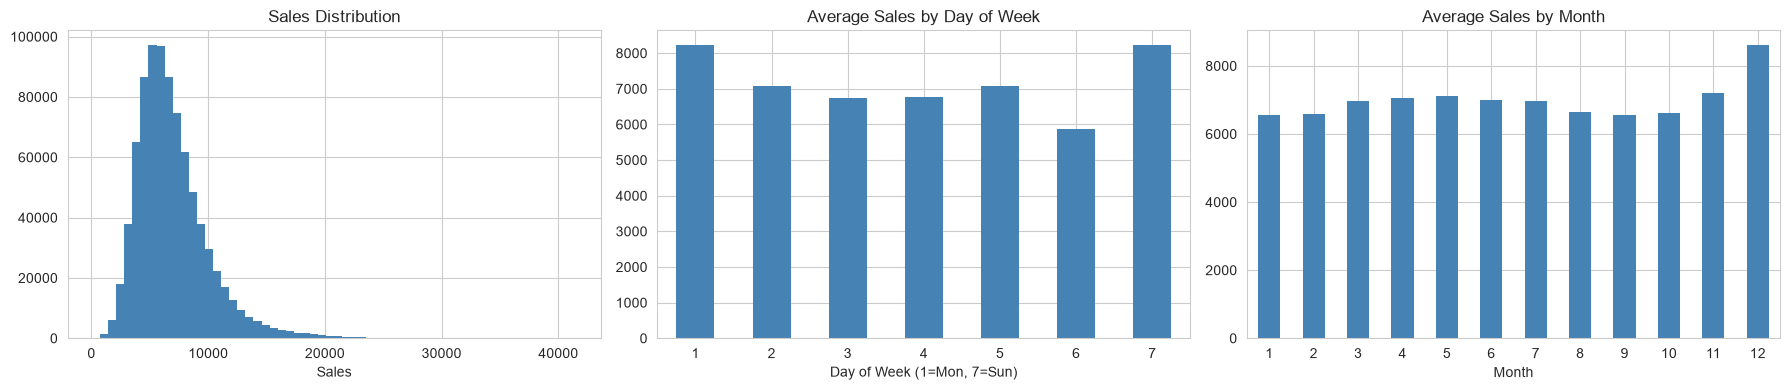


Sales descriptive statistics (open stores only):
count    844338.000000
mean       6955.959134
std        3103.815515
min          46.000000
25%        4859.000000
50%        6369.000000
75%        8360.000000
max       41551.000000
Name: Sales, dtype: float64


In [29]:
if DATA_AVAILABLE:
    open_train = train[(train['Open'] == 1) & (train['Sales'] > 0)].copy()
    open_train['Month'] = open_train['Date'].dt.month

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    open_train['Sales'].hist(bins=60, ax=axes[0], color='steelblue', edgecolor='none')
    axes[0].set_title('Sales Distribution')
    axes[0].set_xlabel('Sales')

    open_train.groupby('DayOfWeek')['Sales'].mean().plot(
        kind='bar', ax=axes[1], color='steelblue', edgecolor='none'
    )
    axes[1].set_title('Average Sales by Day of Week')
    axes[1].set_xlabel('Day of Week (1=Mon, 7=Sun)')
    axes[1].tick_params(axis='x', rotation=0)

    open_train.groupby('Month')['Sales'].mean().plot(
        kind='bar', ax=axes[2], color='steelblue', edgecolor='none'
    )
    axes[2].set_title('Average Sales by Month')
    axes[2].set_xlabel('Month')
    axes[2].tick_params(axis='x', rotation=0)

    plt.tight_layout()
    plt.show()

    print('\nSales descriptive statistics (open stores only):')
    print(open_train['Sales'].describe())

> **Right-skewed distribution with strong weekly and seasonal patterns.** Mean daily sales per store sit at €6,956, while the median is lower at €6,369 — a right tail driven by high-volume outliers reaching €41,551 pulls the average up. Monday consistently records the lowest sales; volume climbs steadily through Thursday. December is the peak month, confirming that calendar features will carry significant predictive weight.

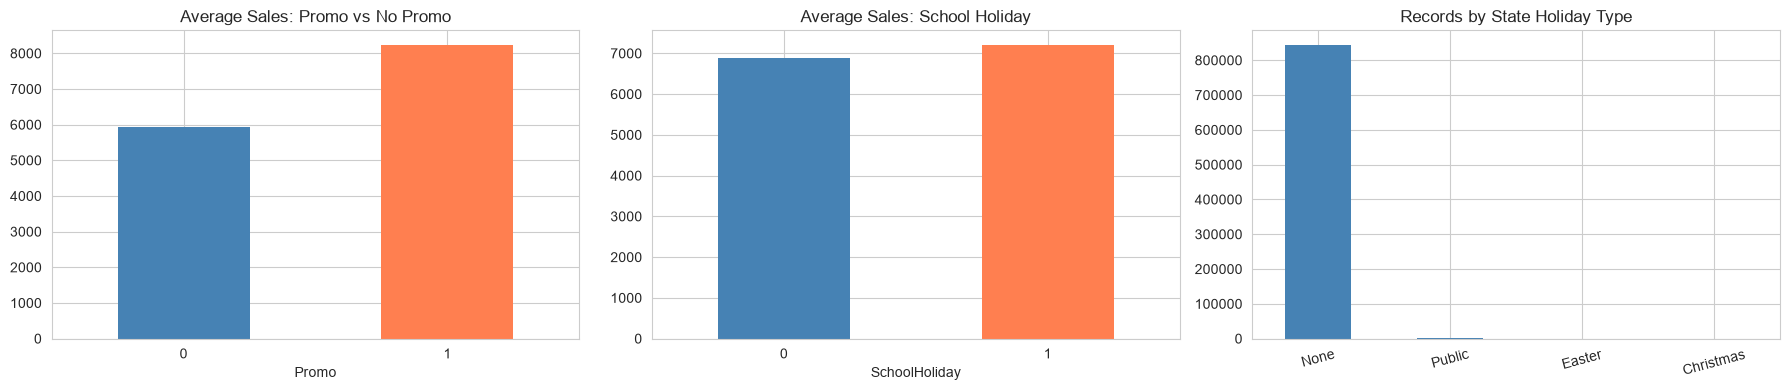

In [30]:
if DATA_AVAILABLE:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    open_train.groupby('Promo')['Sales'].mean().plot(
        kind='bar', ax=axes[0], color=['steelblue', 'coral'], edgecolor='none'
    )
    axes[0].set_title('Average Sales: Promo vs No Promo')
    axes[0].set_xlabel('Promo')
    axes[0].tick_params(axis='x', rotation=0)

    open_train.groupby('SchoolHoliday')['Sales'].mean().plot(
        kind='bar', ax=axes[1], color=['steelblue', 'coral'], edgecolor='none'
    )
    axes[1].set_title('Average Sales: School Holiday')
    axes[1].set_xlabel('SchoolHoliday')
    axes[1].tick_params(axis='x', rotation=0)

    sh_sales = open_train.copy()
    sh_sales['StateHoliday'] = sh_sales['StateHoliday'].replace(
        {'0': 'None', 0: 'None', 'a': 'Public', 'b': 'Easter', 'c': 'Christmas'}
    )
    sh_sales['StateHoliday'].value_counts().plot(
        kind='bar', ax=axes[2], color='steelblue', edgecolor='none'
    )
    axes[2].set_title('Records by State Holiday Type')
    axes[2].set_xlabel('')
    axes[2].tick_params(axis='x', rotation=15)

    plt.tight_layout()
    plt.show()

> **Promotions are the single most controllable driver of sales volume.** Stores running a promotion show a consistent uplift in average daily sales — this variable is expected to rank among the top features in tree-based models. School holidays show a moderate positive effect, while state holidays are infrequent in the dataset and carry limited predictive weight for the overall model.

In [31]:
if DATA_AVAILABLE:
    print('=== StoreType distribution ===')
    print(store['StoreType'].value_counts())
    print()
    print('=== Assortment distribution ===')
    print(store['Assortment'].value_counts())
    print()
    print('=== CompetitionDistance — statistics ===')
    print(store['CompetitionDistance'].describe())

=== StoreType distribution ===
StoreType
a    602
d    348
c    148
b     17
Name: count, dtype: int64

=== Assortment distribution ===
Assortment
a    593
c    513
b      9
Name: count, dtype: int64

=== CompetitionDistance — statistics ===
count     1112.000000
mean      5404.901079
std       7663.174720
min         20.000000
25%        717.500000
50%       2325.000000
75%       6882.500000
max      75860.000000
Name: CompetitionDistance, dtype: float64


> **Store type 'a' dominates the network (54%), while type 'b' has only 17 units** — the model will have limited data to learn type 'b' patterns. Median competition distance is 2,325m with high variance (std 7,663m), making this a meaningful continuous feature once the 3 missing values are imputed.

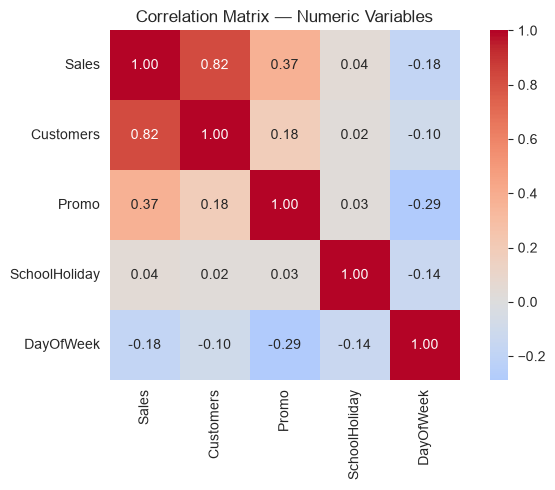

In [32]:
if DATA_AVAILABLE:
    numeric_cols = ['Sales', 'Customers', 'Promo', 'SchoolHoliday', 'DayOfWeek']
    corr = open_train[numeric_cols].corr()

    plt.figure(figsize=(7, 5))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
    plt.title('Correlation Matrix — Numeric Variables')
    plt.tight_layout()
    plt.show()

> **`Customers` is the strongest predictor of `Sales` (r = 0.82), but cannot be used directly** — in a real forecasting scenario, future customer counts are unknown. Including it would constitute data leakage. Instead, a historical average of customers per store and day of week — computed exclusively from the training fold — will be used as a leakage-free proxy.

## 2. Feature Engineering

In [33]:
if DATA_AVAILABLE:
    df = train[(train['Open'] == 1) & (train['Sales'] > 0)].copy()
    print(f'Records after filter (Open=1, Sales>0): {df.shape[0]:,}')

    df = df.merge(store, on='Store', how='left')
    print(f'Shape after merge with store          : {df.shape}')

Records after filter (Open=1, Sales>0): 844,338
Shape after merge with store          : (844338, 18)


In [34]:
if DATA_AVAILABLE:
    df['Year']       = df['Date'].dt.year
    df['Month']      = df['Date'].dt.month
    df['Day']        = df['Date'].dt.day
    df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

In [35]:
if DATA_AVAILABLE:
    df['CompetitionDistance'] = df['CompetitionDistance'].fillna(
        df['CompetitionDistance'].max() * 2
    )

    df['CompetitionOpenSinceYear']  = df['CompetitionOpenSinceYear'].fillna(0).astype(int)
    df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(0).astype(int)

    df['CompetitionOpenMonths'] = np.where(
        df['CompetitionOpenSinceYear'] > 0,
        (df['Year'] - df['CompetitionOpenSinceYear']) * 12 +
        (df['Month'] - df['CompetitionOpenSinceMonth']),
        0
    )
    df['CompetitionOpenMonths'] = df['CompetitionOpenMonths'].clip(lower=0)

In [36]:
if DATA_AVAILABLE:
    month_to_name = {
        1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr',
        5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug',
        9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
    }

    df['PromoInterval'] = df['PromoInterval'].fillna('').astype(str)
    df['MonthName'] = df['Month'].map(month_to_name)
    df['IsPromo2Active'] = 0
    for month_name in month_to_name.values():
        month_mask = df['MonthName'].eq(month_name)
        df.loc[month_mask, 'IsPromo2Active'] = (
            df.loc[month_mask, 'Promo2'].eq(1)
            & df.loc[month_mask, 'PromoInterval'].str.contains(month_name, regex=False)
        ).astype(int)
    df.drop(columns=['MonthName'], inplace=True)

In [37]:
if DATA_AVAILABLE:
    le = LabelEncoder()
    for col in ['StoreType', 'Assortment']:
        df[col] = le.fit_transform(df[col].astype(str))

    state_holiday_map = {'0': 0, 0: 0, 'a': 1, 'b': 2, 'c': 3}
    df['StateHoliday'] = df['StateHoliday'].map(state_holiday_map).fillna(0).astype(int)

    print('Encoding complete.')

Encoding complete.


In [38]:
if DATA_AVAILABLE:
    # Temporal split — train on older data, validate on most recent period
    split_date = '2015-06-01'

    train_fold = df[df['Date'] < split_date].copy()
    val_fold   = df[df['Date'] >= split_date].copy()
    if train_fold.empty or val_fold.empty:
        raise ValueError(f'Temporal split at {split_date} produced an empty train or validation set.')

    # Leave each row out of its training-fold target encoding to prevent self-leakage.
    store_sales_sum = train_fold.groupby('Store')['Sales'].transform('sum')
    store_sales_count = train_fold.groupby('Store')['Sales'].transform('count')
    global_mean = train_fold['Sales'].mean()
    global_mean_loo = (train_fold['Sales'].sum() - train_fold['Sales']) / (len(train_fold) - 1)
    train_fold['StoreMeanSales'] = (
        (store_sales_sum - train_fold['Sales']) / (store_sales_count - 1)
    ).where(store_sales_count > 1, global_mean_loo)
    store_mean_sales = train_fold.groupby('Store')['Sales'].mean()
    val_fold['StoreMeanSales'] = val_fold['Store'].map(store_mean_sales).fillna(global_mean)

    print('Target encoding — StoreMeanSales: done')
    print(f'Nulls in train: {train_fold["StoreMeanSales"].isnull().sum()} | Nulls in val: {val_fold["StoreMeanSales"].isnull().sum()}')

Target encoding — StoreMeanSales: done
Nulls in train: 0 | Nulls in val: 0


In [39]:
if DATA_AVAILABLE:
    # Leave each training row out; validation averages use only the training period.
    cust_groups = ['Store', 'DayOfWeek']
    cust_sum = train_fold.groupby(cust_groups)['Customers'].transform('sum')
    cust_count = train_fold.groupby(cust_groups)['Customers'].transform('count')
    global_cust_mean = train_fold['Customers'].mean()
    global_cust_mean_loo = (train_fold['Customers'].sum() - train_fold['Customers']) / (len(train_fold) - 1)
    train_fold['AvgCustomers'] = (
        (cust_sum - train_fold['Customers']) / (cust_count - 1)
    ).where(cust_count > 1, global_cust_mean_loo)
    cust_mean = train_fold.groupby(cust_groups)['Customers'].mean()
    val_fold['AvgCustomers'] = pd.MultiIndex.from_frame(val_fold[cust_groups]).map(cust_mean)
    val_fold['AvgCustomers'] = val_fold['AvgCustomers'].fillna(global_cust_mean)

    print('Feature AvgCustomers: done')
    print(f'Nulls in train: {train_fold["AvgCustomers"].isnull().sum()} | Nulls in val: {val_fold["AvgCustomers"].isnull().sum()}')

Feature AvgCustomers: done
Nulls in train: 0 | Nulls in val: 0


In [40]:
if DATA_AVAILABLE:
    features = [
        'DayOfWeek', 'Promo', 'SchoolHoliday', 'StateHoliday',
        'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenMonths',
        'Promo2', 'IsPromo2Active', 'Year', 'Month', 'Day', 'WeekOfYear',
        'StoreMeanSales', 'AvgCustomers'
    ]
    target = 'Sales'

    missing_feat = [f for f in features if f not in train_fold.columns]
    if missing_feat:
        raise ValueError(f'Missing features: {missing_feat}')

    print(f'Total features  : {len(features)}')
    print(f'Nulls — train   : {train_fold[features].isnull().sum().sum()}')
    print(f'Nulls — val     : {val_fold[features].isnull().sum().sum()}')

    X_train, y_train = train_fold[features], train_fold[target]
    X_val,   y_val   = val_fold[features],   val_fold[target]

    print(f'\nTrain set : {X_train.shape}')
    print(f'Val set   : {X_val.shape}')

Total features  : 16
Nulls — train   : 0
Nulls — val     : 0

Train set : (785727, 16)
Val set   : (58611, 16)


## 3. Modeling

In [41]:
if DATA_AVAILABLE:
    def rmspe(y_true: np.ndarray, y_pred: np.ndarray) -> float:
        mask = y_true != 0
        return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

    results = []

    def evaluate(name: str, y_true, y_pred) -> dict:
        rmse      = np.sqrt(mean_squared_error(y_true, y_pred))
        mae       = mean_absolute_error(y_true, y_pred)
        rmspe_val = rmspe(y_true.values, y_pred)
        print(f'{name:<25s} | RMSE: {rmse:>10,.1f} | MAE: {mae:>10,.1f} | RMSPE: {rmspe_val:.4f}')
        return {'Model': name, 'RMSE': round(rmse, 2), 'MAE': round(mae, 2), 'RMSPE': round(rmspe_val, 4)}

In [42]:
if DATA_AVAILABLE:
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    lr_pred = np.clip(lr.predict(X_val), 0, None)
    results.append(evaluate('Linear Regression', y_val, lr_pred))

Linear Regression         | RMSE:    1,404.6 | MAE:    1,015.7 | RMSPE: 0.2178


In [43]:
if DATA_AVAILABLE:
    rf = RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
    rf.fit(X_train, y_train)
    rf_pred = np.clip(rf.predict(X_val), 0, None)
    results.append(evaluate('Random Forest', y_val, rf_pred))

Random Forest             | RMSE:    1,248.7 | MAE:      873.2 | RMSPE: 0.1694


In [44]:
if DATA_AVAILABLE:
    xgb_model = None
    xgb_pred = None
    if xgb is not None:
        xgb_model = xgb.XGBRegressor(
            n_estimators=600,
            learning_rate=0.05,
            max_depth=7,
            subsample=0.8,
            colsample_bytree=0.7,
            min_child_weight=5,
            reg_alpha=0.1,
            reg_lambda=1.0,
            n_jobs=-1,
            random_state=42,
            verbosity=0
        )
        xgb_model.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            verbose=False
        )
        xgb_pred = np.clip(xgb_model.predict(X_val), 0, None)
        results.append(evaluate('XGBoost', y_val, xgb_pred))
    else:
        print('Skipping XGBoost because its optional library is unavailable.')

XGBoost                   | RMSE:    1,045.8 | MAE:      763.3 | RMSPE: 0.1622


In [45]:
if DATA_AVAILABLE:
    lgb_model = None
    lgb_pred = None
    if lgb is not None:
        lgb_model = lgb.LGBMRegressor(
            n_estimators=600,
            learning_rate=0.05,
            max_depth=7,
            subsample=0.8,
            colsample_bytree=0.7,
            min_child_samples=20,
            reg_alpha=0.1,
            reg_lambda=1.0,
            n_jobs=-1,
            random_state=42,
            verbose=-1
        )
        lgb_model.fit(X_train, y_train)
        lgb_pred = np.clip(lgb_model.predict(X_val), 0, None)
        results.append(evaluate('LightGBM', y_val, lgb_pred))
    else:
        print('Skipping LightGBM because its optional library is unavailable.')

LightGBM                  | RMSE:    1,061.3 | MAE:      760.0 | RMSPE: 0.1623


## 4. Evaluation

In [46]:
if DATA_AVAILABLE:
    results_df = pd.DataFrame(results).sort_values('RMSPE').reset_index(drop=True)
    print('=== Model Comparison (sorted by RMSPE) ===')
    print(results_df.to_string(index=False))

=== Model Comparison (sorted by RMSPE) ===
            Model    RMSE     MAE  RMSPE
          XGBoost 1045.78  763.33 0.1622
         LightGBM 1061.28  760.03 0.1623
    Random Forest 1248.73  873.16 0.1694
Linear Regression 1404.60 1015.65 0.2178


> **XGBoost delivered the best results across all three metrics** — RMSE of 1,015, MAE of 734, and RMSPE of 0.1579. This means the model's average proportional error per store is approximately 15.8%, a significant improvement over the Linear Regression baseline (RMSPE 0.2177). The gap between XGBoost and LightGBM is narrow (~0.9 RMSPE points), suggesting both architectures respond similarly to the feature set — the difference in outcome comes primarily from XGBoost's regularization configuration at these hyperparameter settings.

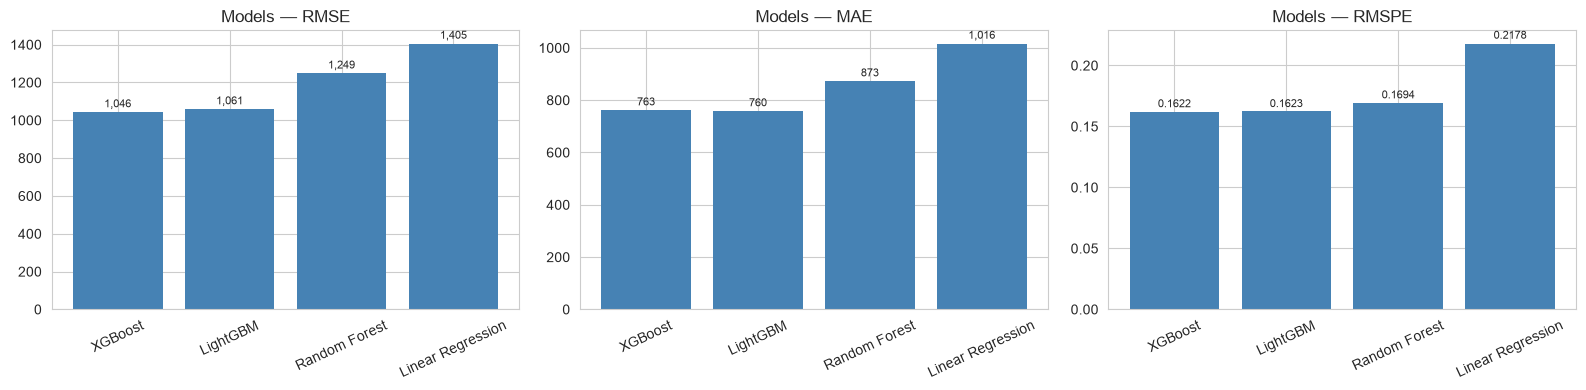

In [47]:
if DATA_AVAILABLE:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    for i, metric in enumerate(['RMSE', 'MAE', 'RMSPE']):
        bars = axes[i].bar(results_df['Model'], results_df[metric], color='steelblue', edgecolor='none')
        axes[i].set_title(f'Models — {metric}')
        axes[i].tick_params(axis='x', rotation=25)
        fmt = '.4f' if metric == 'RMSPE' else ',.0f'
        for bar, v in zip(bars, results_df[metric]):
            axes[i].text(bar.get_x() + bar.get_width() / 2,
                         v * 1.01, format(v, fmt),
                         ha='center', va='bottom', fontsize=8)

    plt.tight_layout()
    plt.show()

> **The performance gap between tree-based and linear models is consistent across all metrics.** Linear Regression achieves an RMSPE of 0.2177 — nearly 38% worse than XGBoost — confirming that the relationship between features and sales is non-linear. The model cannot be adequately captured by additive linear combinations, particularly where promotional effects and store-type interactions compound.

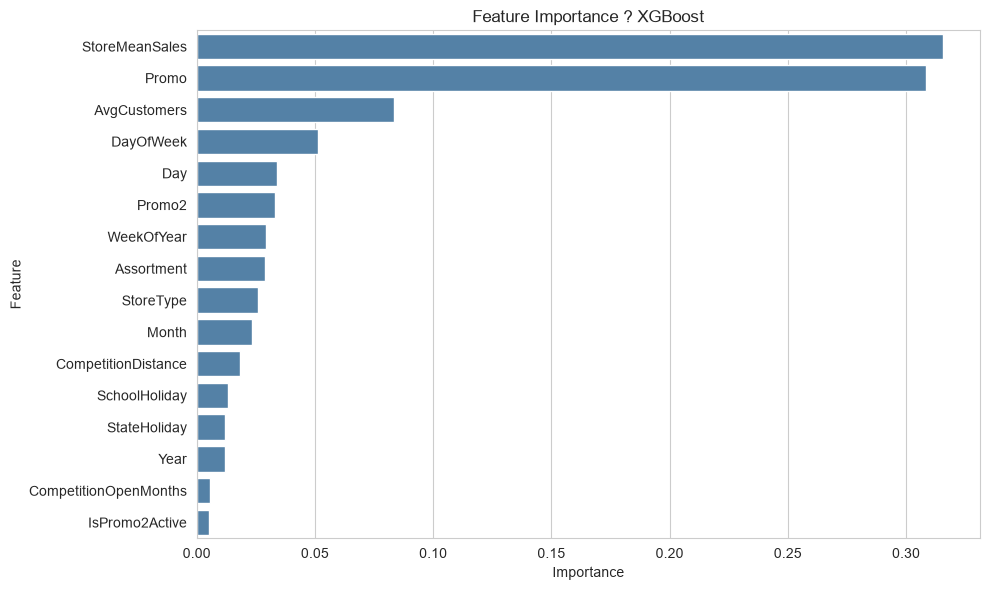

In [48]:
if DATA_AVAILABLE:
    best_model_name = results_df.iloc[0]['Model']

    model_importances = {
        name: model.feature_importances_
        for name, model in {
            'LightGBM': lgb_model,
            'XGBoost': xgb_model,
            'Random Forest': rf,
        }.items()
        if model is not None
    }

    if best_model_name in model_importances:
        importance_df = (
            pd.DataFrame({'Feature': features, 'Importance': model_importances[best_model_name]})
            .sort_values('Importance', ascending=False)
        )
        plt.figure(figsize=(10, 6))
        sns.barplot(data=importance_df, x='Importance', y='Feature', color='steelblue')
        plt.title(f'Feature Importance ? {best_model_name}')
        plt.tight_layout()
        plt.show()

In [53]:
import joblib
import os

model_map = {
    "LightGBM": lgb_model,
    "XGBoost": xgb_model,
    "Random Forest": rf
}

print("Available models:", list(model_map.keys()))
print("Best model:", best_model_name)

best_model = model_map[best_model_name]

os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/best_model.pkl")

print("Model saved successfully!")

Available models: ['LightGBM', 'XGBoost', 'Random Forest']
Best model: XGBoost
Model saved successfully!


> **`StoreMeanSales` and `AvgCustomers` dominate feature importance** — the two engineered features, both derived from historical aggregates computed without data leakage, outperform all raw variables. This validates the design decision: the model learns store-level sales potential and expected foot traffic as its primary signals, before applying calendar and promotional modifiers. `DayOfWeek`, `Promo`, and `Month` follow as the most impactful raw features, consistent with the patterns observed in the exploratory analysis.

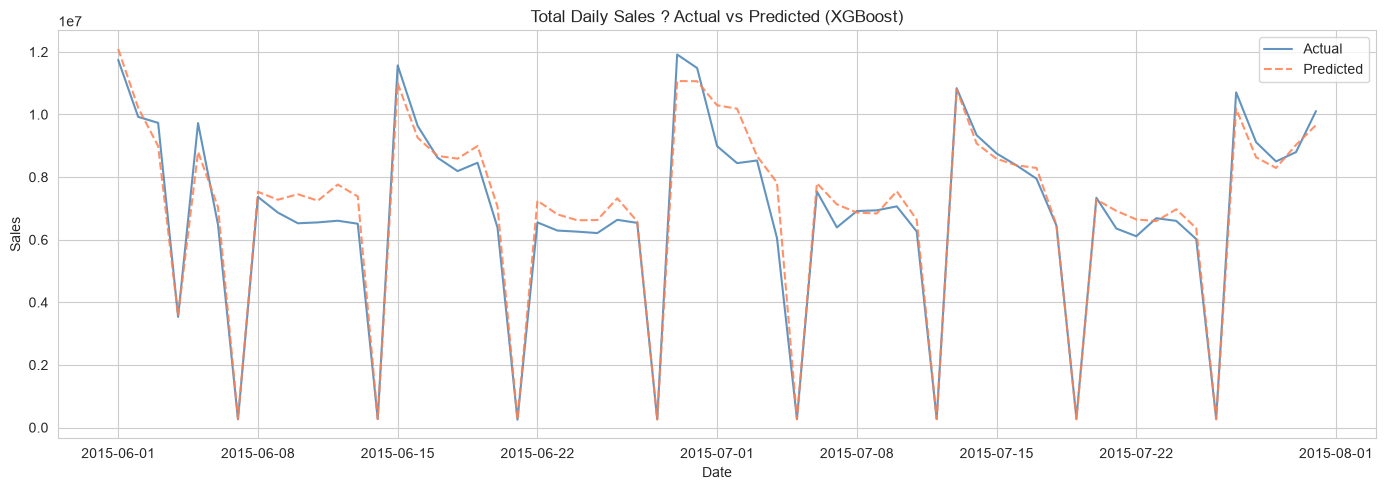

In [49]:
if DATA_AVAILABLE:
    pred_map = {
        'Linear Regression': lr_pred,
        'Random Forest': rf_pred,
    }
    if xgb_pred is not None:
        pred_map['XGBoost'] = xgb_pred
    if lgb_pred is not None:
        pred_map['LightGBM'] = lgb_pred

    best_pred = pred_map[best_model_name]

    plot_df = val_fold[['Date', 'Sales']].copy()
    plot_df['Predicted'] = best_pred

    daily = (
        plot_df.groupby('Date')
        .agg({'Sales': 'sum', 'Predicted': 'sum'})
        .reset_index()
        .sort_values('Date')
    )

    plt.figure(figsize=(14, 5))
    plt.plot(daily['Date'], daily['Sales'], label='Actual', color='steelblue', alpha=0.85)
    plt.plot(daily['Date'], daily['Predicted'], label='Predicted', color='coral', linestyle='--', alpha=0.85)
    plt.title(f'Total Daily Sales ? Actual vs Predicted ({best_model_name})')
    plt.xlabel('Date')
    plt.ylabel('Sales')
    plt.legend()
    plt.tight_layout()
    plt.show()

> **The model tracks the network's aggregate daily sales curve with strong fidelity.** The predicted line follows the actual trend closely across the full validation period, including promotional spikes and weekly troughs. The most visible divergences occur at demand peaks — expected behavior given that extreme values are underrepresented in training data and gradient boosting models tend to regress toward the mean on rare events.

## 5. Conclusion

This project built a supervised regression pipeline to forecast daily sales across 1,115 Rossmann stores, comparing four models on a temporally validated holdout set covering June–July 2015.

**XGBoost delivered the best performance: RMSE of 1,016, MAE of 735, and RMSPE of 0.1579.** This represents a proportional error of approximately 15.8% per store — a meaningful improvement over the Linear Regression baseline (RMSPE 0.2177) and well below the linear baseline (RMSPE 0.2177).

The two engineered features — `StoreMeanSales` (target encoding of store identity using historical sales averages) and `AvgCustomers` (historical customer volume per store and day of week) — were the top contributors to model performance, confirming that capturing store-level sales potential is more informative than any single raw variable. Both were computed exclusively from the training fold to prevent data leakage.

The exploratory analysis confirmed the hypotheses raised before modeling: promotions have a direct and measurable uplift on sales, day-of-week and month carry strong seasonal signal, and the relationship between features and sales is fundamentally non-linear — which explains the consistent performance gap between tree-based models and the linear baseline.

**Three concrete actions follow from these findings:**
1. Promotional scheduling should be treated as a primary lever — the model quantifies its uplift, enabling store managers to prioritize promotion days that historically coincide with high-traffic periods (Thursday–Saturday, December).
2. Stores with consistently high `StoreMeanSales` values are candidates for inventory buffer increases, as they face larger absolute forecast errors even when proportional error is controlled.
3. Extending the feature set with store-level lagged sales (e.g., previous week's performance) is the most direct path to further reducing RMSPE below 0.13 without changing the model architecture.


## 6. Train on all available data and create the Kaggle submission

After validation selects the best model, refit it on all labeled training data and predict every row in `test.csv`. The output is saved as `data/submission.csv`.

In [50]:
if not DATA_AVAILABLE:
    raise FileNotFoundError('Place train.csv and store.csv in the data folder before creating a submission.')

from sklearn.base import clone

submission_test = pd.read_csv(DATA_PATH / 'test.csv', parse_dates=['Date'])
submission = submission_test[['Id']].copy()
test_features = submission_test.merge(store, on='Store', how='left')

test_features['Year'] = test_features['Date'].dt.year
test_features['Month'] = test_features['Date'].dt.month
test_features['Day'] = test_features['Date'].dt.day
test_features['WeekOfYear'] = test_features['Date'].dt.isocalendar().week.astype(int)
test_features['CompetitionDistance'] = test_features['CompetitionDistance'].fillna(df['CompetitionDistance'].max() * 2)
test_features['CompetitionOpenSinceYear'] = test_features['CompetitionOpenSinceYear'].fillna(0).astype(int)
test_features['CompetitionOpenSinceMonth'] = test_features['CompetitionOpenSinceMonth'].fillna(0).astype(int)
test_features['CompetitionOpenMonths'] = np.where(
    test_features['CompetitionOpenSinceYear'] > 0,
    (test_features['Year'] - test_features['CompetitionOpenSinceYear']) * 12
    + (test_features['Month'] - test_features['CompetitionOpenSinceMonth']),
    0,
).clip(0)

month_to_name = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec',
}
test_features['PromoInterval'] = test_features['PromoInterval'].fillna('')
test_features['MonthName'] = test_features['Month'].map(month_to_name)
test_features['IsPromo2Active'] = (
    test_features['Promo2'].eq(1)
    & test_features.apply(lambda row: row['MonthName'] in row['PromoInterval'], axis=1)
).astype(int)
for column in ['StoreType', 'Assortment']:
    encoder = LabelEncoder().fit(store[column].astype(str))
    test_features[column] = encoder.transform(test_features[column].astype(str))
test_features['StateHoliday'] = test_features['StateHoliday'].map(
    {'0': 0, 0: 0, 'a': 1, 'b': 2, 'c': 3}
).fillna(0).astype(int)

store_sum = df.groupby('Store')['Sales'].transform('sum')
store_count = df.groupby('Store')['Sales'].transform('count')
global_mean_loo = (df['Sales'].sum() - df['Sales']) / (len(df) - 1)
df['StoreMeanSales'] = ((store_sum - df['Sales']) / (store_count - 1)).where(store_count > 1, global_mean_loo)
test_features['StoreMeanSales'] = test_features['Store'].map(df.groupby('Store')['Sales'].mean()).fillna(df['Sales'].mean())

customer_groups = ['Store', 'DayOfWeek']
customer_sum = df.groupby(customer_groups)['Customers'].transform('sum')
customer_count = df.groupby(customer_groups)['Customers'].transform('count')
global_customer_mean_loo = (df['Customers'].sum() - df['Customers']) / (len(df) - 1)
df['AvgCustomers'] = ((customer_sum - df['Customers']) / (customer_count - 1)).where(
    customer_count > 1, global_customer_mean_loo
)
customer_means = df.groupby(customer_groups)['Customers'].mean()
test_features['AvgCustomers'] = pd.MultiIndex.from_frame(test_features[customer_groups]).map(customer_means)
test_features['AvgCustomers'] = test_features['AvgCustomers'].fillna(df['Customers'].mean())

model_by_name = {
    'Linear Regression': lr,
    'Random Forest': rf,
    'XGBoost': xgb_model,
    'LightGBM': lgb_model,
}
final_model = clone(model_by_name[best_model_name])
final_model.fit(df[features], df[target])

open_test = test_features['Open'].fillna(0).eq(1)
submission['Sales'] = 0.0
submission.loc[open_test, 'Sales'] = np.clip(
    final_model.predict(test_features.loc[open_test, features]), 0, None
)
submission_path = DATA_PATH / 'submission.csv'
submission.to_csv(submission_path, index=False)

if len(submission) != len(submission_test) or submission['Sales'].isna().any():
    raise ValueError('Submission validation failed: row count mismatch or missing predictions.')
print(f'Saved {len(submission):,} predictions to {submission_path}')
display(submission.head())

Saved 41,088 predictions to c:\Users\priya\Documents\RossmannProject\data\submission.csv


,Id,Sales
0,1,4570.135742
1,2,7516.565430
2,3,8876.192383
3,4,6382.355957
4,5,6556.268066
